In [4]:
from pathlib import Path

print("Cartella del notebook:", Path.cwd())

Cartella del notebook: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/notebooks/marco


In [5]:
%pip install requests pandas

Note: you may need to restart the kernel to use updated packages.


In [6]:
from getpass import getpass

token = getpass("Inserisci il token ENTSO-E: ")

In [7]:
import requests
import pandas as pd

In [8]:
import requests

In [9]:
url = "https://web-api.tp.entsoe.eu/api"

params = {
    "securityToken": token,
    "documentType": "A65",
    "processType": "A16",
    "outBiddingZone_Domain": "10YIT-GRTN-----B",
    "periodStart": "202401150000",
    "periodEnd": "202401220000",
}

In [10]:
response = requests.get(
    url,
    params=params,
    timeout=60,
)

print("Stato HTTP:", response.status_code)
print(response.text[:2000])

Stato HTTP: 200
<?xml version="1.0" encoding="utf-8"?>
<GL_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-6:generationloaddocument:3:0">
  <mRID>0d60f8ae459243d088b862014bd588a5</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A65</type>
  <process.processType>A16</process.processType>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
  <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>
  <receiver_MarketParticipant.marketRole.type>A33</receiver_MarketParticipant.marketRole.type>
  <createdDateTime>2026-10-16T10:30:30Z</createdDateTime>
  <time_Period.timeInterval>
    <start>2024-01-15T00:00Z</start>
    <end>2024-01-22T00:00Z</end>
  </time_Period.timeInterval>
    <TimeSeries>
      <mRID>1</mRID>
      <businessType>A04</businessType>
      <objectAggregation>A01</objectAggregation>


In [11]:
from pathlib import Path

notebook_dir = Path.cwd()
project_root = notebook_dir.parent.parent

# Verifichiamo di aver individuato davvero il repository.
if not (project_root / ".git").exists():
    raise RuntimeError(
        "Repository non trovato: controlla la posizione del notebook."
    )

raw_dir = project_root / "data" / "raw" / "entsoe"
raw_dir.mkdir(parents=True, exist_ok=True)

raw_path = raw_dir / "actual_load_20240115_20240122.xml"

# Modalità 'xb': crea il file, ma impedisce di sovrascriverne uno esistente.
if raw_path.exists():
    print("Il file esiste già: non è stato sovrascritto.")
else:
    with raw_path.open("xb") as file:
        file.write(response.content)

    print("File originale salvato:", raw_path)

File originale salvato: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/raw/entsoe/actual_load_20240115_20240122.xml


In [12]:
import xml.etree.ElementTree as ET

tree = ET.parse(raw_path)
root = tree.getroot()

ns = {
    "e": root.tag.split("}")[0].removeprefix("{")
}

print("Elemento principale:", root.tag)

Elemento principale: {urn:iec62325.351:tc57wg16:451-6:generationloaddocument:3:0}GL_MarketDocument


In [13]:
series_list = root.findall("e:TimeSeries", ns)

print("Numero di serie:", len(series_list))

for series in series_list:
    print("\nSerie:", series.findtext("e:mRID", namespaces=ns))
    print(
        "Area:",
        series.findtext("e:outBiddingZone_Domain.mRID", namespaces=ns),
    )
    print(
        "Unità:",
        series.findtext("e:quantity_Measure_Unit.name", namespaces=ns),
    )
    print("Tipo di curva:", series.findtext("e:curveType", namespaces=ns))

    for period in series.findall("e:Period", ns):
        start = period.findtext("e:timeInterval/e:start", namespaces=ns)
        end = period.findtext("e:timeInterval/e:end", namespaces=ns)
        resolution = period.findtext("e:resolution", namespaces=ns)

        points = period.findall("e:Point", ns)
        positions = [
            int(point.findtext("e:position", namespaces=ns))
            for point in points
        ]

        print("Periodo:", start, "→", end)
        print("Risoluzione:", resolution)
        print("Numero di punti:", len(points))
        print("Prime 10 posizioni:", positions[:10])
        print("Ultime 10 posizioni:", positions[-10:])
        print("Posizioni duplicate:", len(positions) - len(set(positions)))

Numero di serie: 1

Serie: 1
Area: 10YIT-GRTN-----B
Unità: MAW
Tipo di curva: A03
Periodo: 2024-01-15T00:00Z → 2024-01-22T00:00Z
Risoluzione: PT60M
Numero di punti: 168
Prime 10 posizioni: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Ultime 10 posizioni: [159, 160, 161, 162, 163, 164, 165, 166, 167, 168]
Posizioni duplicate: 0


In [2]:
from pathlib import Path

current_dir = Path.cwd()

print("Current working directory:", current_dir)

Current working directory: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/notebooks/marco


In [4]:
project_root = current_dir.parent.parent

raw_dir = project_root / "data" / "raw" / "entsoe"
processed_dir = project_root / "data" / "processed"

if not raw_dir.is_dir():
    raise FileNotFoundError(f"Raw data folder not found: {raw_dir}")

processed_dir.mkdir(parents=True, exist_ok=True)

print("Raw data folder:", raw_dir)
print("Processed data folder:", processed_dir)

Raw data folder: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/raw/entsoe
Processed data folder: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/processed


In [6]:
import xml.etree.ElementTree as ET

raw_path = raw_dir / "actual_load_20240115_20240122.xml"

tree = ET.parse(raw_path)
root = tree.getroot()

print("File loaded:", raw_path.name)
print("Root element:", root.tag)

File loaded: actual_load_20240115_20240122.xml
Root element: {urn:iec62325.351:tc57wg16:451-6:generationloaddocument:3:0}GL_MarketDocument


In [8]:
# Extract the namespace from the root element.
namespace_uri = root.tag.split("}")[0].removeprefix("{")
ns = {"e": namespace_uri}

# Read the document's data type and process type.
document_type = root.findtext("e:type", namespaces=ns)
process_type = root.findtext("e:process.processType", namespaces=ns)

# Find all time series in the document.
series_list = root.findall("e:TimeSeries", namespaces=ns)

print("Document type:", document_type)
print("Process type:", process_type)
print("Number of time series:", len(series_list))

Document type: A65
Process type: A16
Number of time series: 1


In [10]:
# Select the first time series.
series = series_list[0]

# Read the series metadata.
area = series.findtext("e:outBiddingZone_Domain.mRID", namespaces=ns)
unit = series.findtext("e:quantity_Measure_Unit.name", namespaces=ns)
curve_type = series.findtext("e:curveType", namespaces=ns)

# Find all periods within this series.
periods = series.findall("e:Period", namespaces=ns)

print("Area:", area)
print("Unit:", unit)
print("Curve type:", curve_type)
print("Number of periods:", len(periods))

for period in periods:
    start = period.findtext("e:timeInterval/e:start", namespaces=ns)
    end = period.findtext("e:timeInterval/e:end", namespaces=ns)
    resolution = period.findtext("e:resolution", namespaces=ns)
    points = period.findall("e:Point", namespaces=ns)

    print("\nPeriod start:", start)
    print("Period end:", end)
    print("Resolution:", resolution)
    print("Number of points:", len(points))

Area: 10YIT-GRTN-----B
Unit: MAW
Curve type: A03
Number of periods: 1

Period start: 2024-01-15T00:00Z
Period end: 2024-01-22T00:00Z
Resolution: PT60M
Number of points: 168


In [12]:
import pandas as pd

# Select the only period in this sample.
period = periods[0]
points = period.findall("e:Point", namespaces=ns)

# Extract each point into a dictionary.
records = []

for point in points:
    position = int(point.findtext("e:position", namespaces=ns))
    quantity_text = point.findtext("e:quantity", namespaces=ns)

    # Preserve missing quantities as NaN.
    quantity = (
        float(quantity_text)
        if quantity_text is not None and quantity_text.strip()
        else float("nan")
    )

    records.append({
        "position": position,
        "actual_load_mw": quantity,
    })

# Convert the list of records into a table.
points_df = pd.DataFrame(records)

print("Number of rows:", len(points_df))
print("Duplicate positions:", points_df["position"].duplicated().sum())
print("Missing quantities:", points_df["actual_load_mw"].isna().sum())

display(points_df.head())

Number of rows: 168
Duplicate positions: 0
Missing quantities: 0


,position,actual_load_mw
0,1,22372.0
1,2,21618.0
2,3,21441.0
3,4,22262.0
4,5,24831.0


In [14]:
# Read the period boundaries as timezone-aware timestamps.
start = pd.to_datetime(
    period.findtext("e:timeInterval/e:start", namespaces=ns),
    utc=True,
)
end = pd.to_datetime(
    period.findtext("e:timeInterval/e:end", namespaces=ns),
    utc=True,
)

# Convert the XML resolution into a duration.
resolution = pd.Timedelta(
    period.findtext("e:resolution", namespaces=ns)
)

# Check that the period contains a whole number of intervals.
if resolution <= pd.Timedelta(0):
    raise ValueError("Resolution must be positive.")

if (end - start) % resolution != pd.Timedelta(0):
    raise ValueError("Period duration is not divisible by its resolution.")

expected_count = int((end - start) / resolution)

# Check positions before converting them into timestamps.
ordered_points = points_df.sort_values("position").reset_index(drop=True)
expected_positions = list(range(1, expected_count + 1))

if ordered_points["position"].tolist() != expected_positions:
    raise ValueError(
        "Positions are not a complete sequence. "
        "Inspect duplicates, invalid positions, or A03 blocks before proceeding."
    )

# Build the timestamped table without changing points_df.
actual_sample = ordered_points.copy()
actual_sample["timestamp_utc"] = (
    start + (actual_sample["position"] - 1) * resolution
)

actual_sample = actual_sample[["timestamp_utc", "actual_load_mw"]]

print("Expected intervals:", expected_count)
print("Actual rows:", len(actual_sample))
print("Missing load values:", actual_sample["actual_load_mw"].isna().sum())
print("First timestamp:", actual_sample["timestamp_utc"].min())
print("Last timestamp:", actual_sample["timestamp_utc"].max())

display(actual_sample.head())

Expected intervals: 168
Actual rows: 168
Missing load values: 0
First timestamp: 2024-01-15 00:00:00+00:00
Last timestamp: 2024-01-21 23:00:00+00:00


,timestamp_utc,actual_load_mw
0,2024-01-15 00:00:00+00:00,22372.0
1,2024-01-15 01:00:00+00:00,21618.0
2,2024-01-15 02:00:00+00:00,21441.0
3,2024-01-15 03:00:00+00:00,22262.0
4,2024-01-15 04:00:00+00:00,24831.0


In [15]:
import requests
from getpass import getpass

token = getpass("Enter your ENTSO-E API token: ")

In [17]:
forecast_raw_path = raw_dir / "day_ahead_load_20240115_20240122.xml"

# Reuse the original file if it has already been downloaded.
if forecast_raw_path.exists():
    print("Using existing file:", forecast_raw_path.name)

else:
    forecast_params = {
        "securityToken": token,
        "documentType": "A65",
        "processType": "A01",
        "outBiddingZone_Domain": "10YIT-GRTN-----B",
        "periodStart": "202401150000",
        "periodEnd": "202401220000",
    }

    forecast_response = requests.get(
        "https://web-api.tp.entsoe.eu/api",
        params=forecast_params,
        timeout=60,
    )

    print("HTTP status:", forecast_response.status_code)

    if forecast_response.status_code != 200:
        print(forecast_response.text[:2000])
        raise RuntimeError("Forecast download failed. Inspect the response.")

    # Inspect the response before saving it as a data file.
    forecast_root = ET.fromstring(forecast_response.content)
    forecast_ns = {
        "e": forecast_root.tag.split("}")[0].removeprefix("{")
    }

    forecast_series = forecast_root.findall(
        "e:TimeSeries", namespaces=forecast_ns
    )

    if not forecast_series:
        print(forecast_response.text[:2000])
        raise RuntimeError("The response contains no time series.")

    # Save the original response without overwriting an existing file.
    with forecast_raw_path.open("xb") as file:
        file.write(forecast_response.content)

    print("Raw forecast saved:", forecast_raw_path.name)

Using existing file: day_ahead_load_20240115_20240122.xml


In [18]:
# Read the saved forecast file.
forecast_tree = ET.parse(forecast_raw_path)
forecast_root = forecast_tree.getroot()

forecast_ns = {
    "e": forecast_root.tag.split("}")[0].removeprefix("{")
}

forecast_document_type = forecast_root.findtext(
    "e:type", namespaces=forecast_ns
)
forecast_process_type = forecast_root.findtext(
    "e:process.processType", namespaces=forecast_ns
)

forecast_series_list = forecast_root.findall(
    "e:TimeSeries", namespaces=forecast_ns
)

print("Document type:", forecast_document_type)
print("Process type:", forecast_process_type)
print("Number of time series:", len(forecast_series_list))

# Inspect every series and period.
for forecast_series in forecast_series_list:
    forecast_area = forecast_series.findtext(
        "e:outBiddingZone_Domain.mRID", namespaces=forecast_ns
    )
    forecast_unit = forecast_series.findtext(
        "e:quantity_Measure_Unit.name", namespaces=forecast_ns
    )
    forecast_curve_type = forecast_series.findtext(
        "e:curveType", namespaces=forecast_ns
    )

    print("\nArea:", forecast_area)
    print("Matches actual-load area:", forecast_area == area)
    print("Unit:", forecast_unit)
    print("Curve type:", forecast_curve_type)

    forecast_periods = forecast_series.findall(
        "e:Period", namespaces=forecast_ns
    )
    print("Number of periods:", len(forecast_periods))

    for forecast_period in forecast_periods:
        forecast_start = forecast_period.findtext(
            "e:timeInterval/e:start", namespaces=forecast_ns
        )
        forecast_end = forecast_period.findtext(
            "e:timeInterval/e:end", namespaces=forecast_ns
        )
        forecast_resolution = forecast_period.findtext(
            "e:resolution", namespaces=forecast_ns
        )
        forecast_points = forecast_period.findall(
            "e:Point", namespaces=forecast_ns
        )

        print("Period start:", forecast_start)
        print("Period end:", forecast_end)
        print("Resolution:", forecast_resolution)
        print("Number of points:", len(forecast_points))

Document type: A65
Process type: A01
Number of time series: 1

Area: 10YIT-GRTN-----B
Matches actual-load area: True
Unit: MAW
Curve type: A03
Number of periods: 1
Period start: 2024-01-15T00:00Z
Period end: 2024-01-22T00:00Z
Resolution: PT60M
Number of points: 168


In [19]:
# Select the only series and period in this sample.
forecast_series = forecast_series_list[0]
forecast_period = forecast_series.findall(
    "e:Period", namespaces=forecast_ns
)[0]

# Extract the positions and forecast values.
forecast_records = []

for point in forecast_period.findall("e:Point", namespaces=forecast_ns):
    position = int(point.findtext("e:position", namespaces=forecast_ns))
    quantity_text = point.findtext("e:quantity", namespaces=forecast_ns)

    quantity = (
        float(quantity_text)
        if quantity_text is not None and quantity_text.strip()
        else float("nan")
    )

    forecast_records.append({
        "position": position,
        "terna_forecast_mw": quantity,
    })

forecast_points_df = pd.DataFrame(forecast_records)

# Read the time boundaries and resolution.
forecast_start = pd.to_datetime(
    forecast_period.findtext(
        "e:timeInterval/e:start", namespaces=forecast_ns
    ),
    utc=True,
)
forecast_end = pd.to_datetime(
    forecast_period.findtext(
        "e:timeInterval/e:end", namespaces=forecast_ns
    ),
    utc=True,
)
forecast_resolution = pd.Timedelta(
    forecast_period.findtext("e:resolution", namespaces=forecast_ns)
)

if forecast_resolution <= pd.Timedelta(0):
    raise ValueError("Resolution must be positive.")

if forecast_end <= forecast_start:
    raise ValueError("Period end must be after its start.")

if (forecast_end - forecast_start) % forecast_resolution != pd.Timedelta(0):
    raise ValueError("Period duration is not divisible by its resolution.")

# Verify that every expected position appears exactly once.
expected_count = int(
    (forecast_end - forecast_start) / forecast_resolution
)

ordered_forecast = (
    forecast_points_df
    .sort_values("position")
    .reset_index(drop=True)
)

if ordered_forecast["position"].tolist() != list(range(1, expected_count + 1)):
    raise ValueError(
        "Positions are not a complete sequence. "
        "Inspect duplicates, invalid positions, or A03 blocks before proceeding."
    )

# Translate positions into UTC timestamps.
forecast_sample = ordered_forecast.copy()

forecast_sample["timestamp_utc"] = (
    forecast_start
    + (forecast_sample["position"] - 1) * forecast_resolution
)

forecast_sample = forecast_sample[
    ["timestamp_utc", "terna_forecast_mw"]
]

print("Expected intervals:", expected_count)
print("Forecast rows:", len(forecast_sample))
print("Missing forecast values:", forecast_sample["terna_forecast_mw"].isna().sum())
print("First timestamp:", forecast_sample["timestamp_utc"].min())
print("Last timestamp:", forecast_sample["timestamp_utc"].max())

display(forecast_sample.head())

Expected intervals: 168
Forecast rows: 168
Missing forecast values: 0
First timestamp: 2024-01-15 00:00:00+00:00
Last timestamp: 2024-01-21 23:00:00+00:00


,timestamp_utc,terna_forecast_mw
0,2024-01-15 00:00:00+00:00,22615.0
1,2024-01-15 01:00:00+00:00,21997.0
2,2024-01-15 02:00:00+00:00,21987.0
3,2024-01-15 03:00:00+00:00,22571.0
4,2024-01-15 04:00:00+00:00,24658.0


In [20]:
# Define the sample period explicitly.
sample_start = pd.Timestamp("2024-01-15T00:00:00Z")
sample_end = pd.Timestamp("2024-01-22T00:00:00Z")

# Create every expected hourly timestamp, excluding the end boundary.
hourly_timeline = pd.DataFrame({
    "timestamp_utc": pd.date_range(
        start=sample_start,
        end=sample_end,
        freq="h",
        inclusive="left",
    )
})

# Check that neither source contains timestamps outside this timeline.
for name, frame in [
    ("Actual load", actual_sample),
    ("Terna forecast", forecast_sample),
]:
    outside_timeline = ~frame["timestamp_utc"].isin(
        hourly_timeline["timestamp_utc"]
    )

    if outside_timeline.any():
        raise ValueError(f"{name} contains unexpected timestamps.")

# Match both series to the complete timeline.
electricity_sample = hourly_timeline.merge(
    actual_sample,
    on="timestamp_utc",
    how="left",
    validate="one_to_one",
)

electricity_sample = electricity_sample.merge(
    forecast_sample,
    on="timestamp_utc",
    how="left",
    validate="one_to_one",
)

print("Total rows:", len(electricity_sample))
print(
    "Duplicate timestamps:",
    electricity_sample["timestamp_utc"].duplicated().sum(),
)
print("\nMissing values per column:")
print(electricity_sample.isna().sum())

display(electricity_sample.head())

Total rows: 168
Duplicate timestamps: 0

Missing values per column:
timestamp_utc        0
actual_load_mw       0
terna_forecast_mw    0
dtype: int64


,timestamp_utc,actual_load_mw,terna_forecast_mw
0,2024-01-15 00:00:00+00:00,22372.0,22615.0
1,2024-01-15 01:00:00+00:00,21618.0,21997.0
2,2024-01-15 02:00:00+00:00,21441.0,21987.0
3,2024-01-15 03:00:00+00:00,22262.0,22571.0
4,2024-01-15 04:00:00+00:00,24831.0,24658.0


In [21]:
load_columns = ["actual_load_mw", "terna_forecast_mw"]

# Summarise the distribution of each series.
display(electricity_sample[load_columns].describe())

# Keep quality flags in a separate table.
quality_flags = electricity_sample[["timestamp_utc"]].copy()

for column in load_columns:
    values = electricity_sample[column]

    quality_flags[f"{column}_non_positive"] = values.le(0)
    quality_flags[f"{column}_infinite"] = values.isin(
        [float("inf"), float("-inf")]
    )

# Identify rows with at least one flag.
flag_columns = quality_flags.columns.drop("timestamp_utc")
flagged_rows = quality_flags[flag_columns].any(axis=1)

print("Flag counts:")
print(quality_flags[flag_columns].sum())
print("\nHours with at least one flag:", flagged_rows.sum())

display(electricity_sample.loc[flagged_rows])

,actual_load_mw,terna_forecast_mw
count,168.000000,168.000000
mean,34353.750000,34736.464286
std,7466.350922,7497.043713
min,21441.000000,21987.000000
25%,27368.000000,27734.000000
50%,33641.500000,34184.000000
75%,41845.250000,42242.000000
max,45619.000000,45928.000000


Flag counts:
actual_load_mw_non_positive       0
actual_load_mw_infinite           0
terna_forecast_mw_non_positive    0
terna_forecast_mw_infinite        0
dtype: int64

Hours with at least one flag: 0


,timestamp_utc,actual_load_mw,terna_forecast_mw


Matplotlib is building the font cache; this may take a moment.


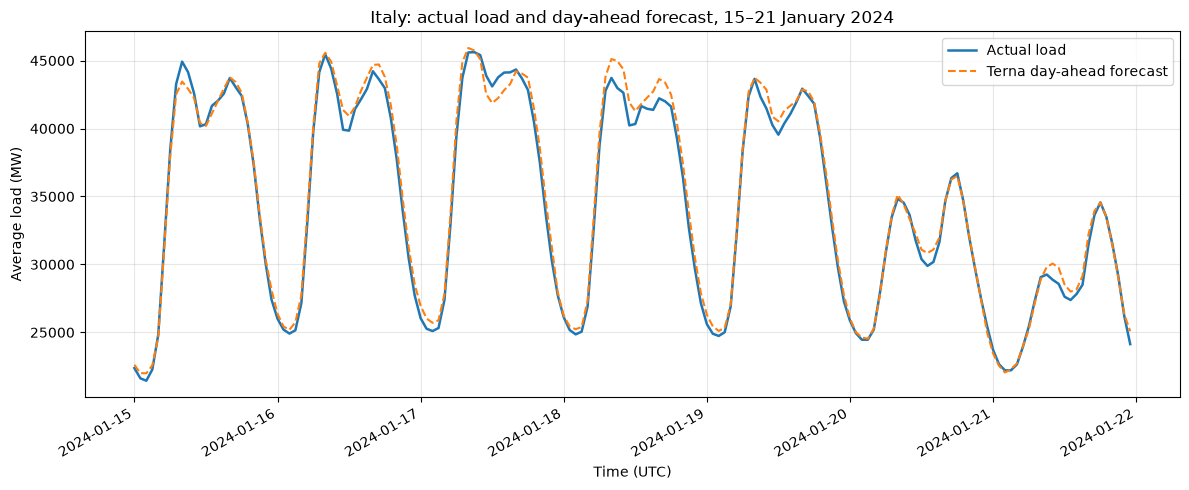

In [22]:
import matplotlib.pyplot as plt

# Create a figure containing one plotting area.
fig, ax = plt.subplots(figsize=(12, 5))

# Plot actual demand.
ax.plot(
    electricity_sample["timestamp_utc"],
    electricity_sample["actual_load_mw"],
    label="Actual load",
    color="tab:blue",
    linewidth=1.8,
)

# Plot Terna's forecast on the same axes.
ax.plot(
    electricity_sample["timestamp_utc"],
    electricity_sample["terna_forecast_mw"],
    label="Terna day-ahead forecast",
    color="tab:orange",
    linestyle="--",
    linewidth=1.5,
)

ax.set_title("Italy: actual load and day-ahead forecast, 15–21 January 2024")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Average load (MW)")
ax.legend()
ax.grid(True, alpha=0.3)

# Improve spacing and date-label readability.
fig.autofmt_xdate()
fig.tight_layout()

plt.show()

In [24]:
import pandas as pd

# Define the full dataset period: start included, end excluded.
dataset_start = pd.Timestamp("2022-01-01T00:00:00Z")
dataset_end = pd.Timestamp("2026-01-01T00:00:00Z")

# Generate the start of every month, including the final boundary.
month_boundaries = pd.date_range(
    start=dataset_start,
    end=dataset_end,
    freq="MS",
)

# Pair each boundary with the following boundary.
download_windows = list(
    zip(month_boundaries[:-1], month_boundaries[1:])
)

print("Number of monthly windows:", len(download_windows))
print("First window:", download_windows[0])
print("Last window:", download_windows[-1])
print("Planned requests for two series:", len(download_windows) * 2)

Number of monthly windows: 48
First window: (Timestamp('2022-01-01 00:00:00+0000', tz='UTC'), Timestamp('2022-02-01 00:00:00+0000', tz='UTC'))
Last window: (Timestamp('2025-12-01 00:00:00+0000', tz='UTC'), Timestamp('2026-01-01 00:00:00+0000', tz='UTC'))
Planned requests for two series: 96


In [25]:
import requests
import xml.etree.ElementTree as ET

def download_load_month(series_name, process_type, start, end):
    """Download one monthly load response, preserving its original bytes."""

    filename = (
        f"{series_name}_{start.strftime('%Y%m%d')}_"
        f"{end.strftime('%Y%m%d')}.xml"
    )
    destination = raw_dir / filename

    # Reuse an existing file, but check its contents below.
    if destination.exists():
        content = destination.read_bytes()
        status = "existing"

    else:
        params = {
            "securityToken": token,
            "documentType": "A65",
            "processType": process_type,
            "outBiddingZone_Domain": "10YIT-GRTN-----B",
            "periodStart": start.strftime("%Y%m%d%H%M"),
            "periodEnd": end.strftime("%Y%m%d%H%M"),
        }

        try:
            response = requests.get(
                "https://web-api.tp.entsoe.eu/api",
                params=params,
                timeout=60,
            )
        except requests.RequestException:
            # Avoid displaying exception URLs that may contain the token.
            return {
                "file": filename,
                "status": "request_failed",
                "detail": "Connection or timeout error; retry required.",
            }

        content = response.content

        if response.status_code != 200:
            return {
                "file": filename,
                "status": "http_error",
                "detail": f"HTTP {response.status_code}; investigate before retrying.",
            }

        status = "downloaded"

    # Check that the response is valid XML.
    try:
        document = ET.fromstring(content)
    except ET.ParseError:
        return {
            "file": filename,
            "status": "invalid_xml",
            "detail": "The response could not be parsed as XML.",
        }

    namespace = {
        "e": document.tag.split("}")[0].removeprefix("{")
    }

    time_series = document.findall("e:TimeSeries", namespace)

    if not time_series:
        reasons = document.findall(".//e:Reason/e:text", namespace)
        explanation = "; ".join(
            reason.text for reason in reasons if reason.text
        )

        return {
            "file": filename,
            "status": "no_time_series",
            "detail": explanation or "No time series found; investigate.",
        }

    document_type = document.findtext("e:type", namespaces=namespace)
    returned_process = document.findtext(
        "e:process.processType", namespaces=namespace
    )

    if document_type != "A65" or returned_process != process_type:
        return {
            "file": filename,
            "status": "unexpected_document",
            "detail": "Document type or process type does not match the request.",
        }

    # Preserve the original response without overwriting any file.
    if status == "downloaded":
        with destination.open("xb") as file:
            file.write(content)

    return {
        "file": filename,
        "status": status,
        "detail": f"{len(time_series)} time series; detailed checks pending.",
    }

In [26]:
first_start, first_end = download_windows[0]

test_results = []

for series_name, process_type in [
    ("actual_load", "A16"),
    ("day_ahead_load", "A01"),
]:
    result = download_load_month(
        series_name,
        process_type,
        first_start,
        first_end,
    )
    test_results.append(result)

display(pd.DataFrame(test_results))

,file,status,detail
0,actual_load_20220101_20220201.xml,downloaded,1 time series; detailed checks pending.
1,day_ahead_load_20220101_20220201.xml,downloaded,1 time series; detailed checks pending.


In [27]:
import time

series_settings = [
    ("actual_load", "A16"),
    ("day_ahead_load", "A01"),
]

download_results = []
total = len(download_windows) * len(series_settings)

# Give each run its own log filename.
run_id = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
log_path = processed_dir / f"entsoe_download_log_{run_id}.csv"

for month_start, month_end in download_windows:
    for series_name, process_type in series_settings:
        result = download_load_month(
            series_name,
            process_type,
            month_start,
            month_end,
        )

        # Add context to the result returned by the function.
        result["series"] = series_name
        result["start_utc"] = month_start.strftime("%Y-%m-%dT%H:%M:%SZ")
        result["end_utc"] = month_end.strftime("%Y-%m-%dT%H:%M:%SZ")

        download_results.append(result)

        # Save progress after every result.
        download_log = pd.DataFrame(download_results)
        download_log.to_csv(log_path, index=False)

        completed = len(download_results)
        print(
            f"[{completed}/{total}] "
            f"{result['file']}: {result['status']}",
            flush=True,
        )

        # Pause briefly between requests.
        time.sleep(1)

print("\nDownload status counts:")
print(download_log["status"].value_counts())

successful_statuses = ["downloaded", "existing"]
needs_attention = download_log.loc[
    ~download_log["status"].isin(successful_statuses)
]

print("\nEntries needing investigation:", len(needs_attention))
display(needs_attention)

print("Download log saved:", log_path)

[1/96] actual_load_20220101_20220201.xml: existing
[2/96] day_ahead_load_20220101_20220201.xml: existing
[3/96] actual_load_20220201_20220301.xml: downloaded
[4/96] day_ahead_load_20220201_20220301.xml: downloaded
[5/96] actual_load_20220301_20220401.xml: downloaded
[6/96] day_ahead_load_20220301_20220401.xml: downloaded
[7/96] actual_load_20220401_20220501.xml: downloaded
[8/96] day_ahead_load_20220401_20220501.xml: downloaded
[9/96] actual_load_20220501_20220601.xml: downloaded
[10/96] day_ahead_load_20220501_20220601.xml: downloaded
[11/96] actual_load_20220601_20220701.xml: downloaded
[12/96] day_ahead_load_20220601_20220701.xml: downloaded
[13/96] actual_load_20220701_20220801.xml: downloaded
[14/96] day_ahead_load_20220701_20220801.xml: downloaded
[15/96] actual_load_20220801_20220901.xml: downloaded
[16/96] day_ahead_load_20220801_20220901.xml: downloaded
[17/96] actual_load_20220901_20221001.xml: downloaded
[18/96] day_ahead_load_20220901_20221001.xml: downloaded
[19/96] actual

,file,status,detail,series,start_utc,end_utc


Download log saved: /Users/marcohlovatskyi/Desktop/Bocconi/ML Projects/Energy/italy-electricity-load-forecasting/data/processed/entsoe_download_log_20261023T175153551386Z.csv


In [29]:
metadata_records = []

# Inspect only the monthly files listed in the download log.
for entry in download_log.to_dict("records"):
    file_path = raw_dir / entry["file"]

    document = ET.parse(file_path).getroot()
    namespace = {
        "e": document.tag.split("}")[0].removeprefix("{")
    }

    for series in document.findall("e:TimeSeries", namespace):
        # Metadata shared by all periods in this series.
        area_code = series.findtext(
            "e:outBiddingZone_Domain.mRID", namespaces=namespace
        )
        unit_code = series.findtext(
            "e:quantity_Measure_Unit.name", namespaces=namespace
        )
        curve_type = series.findtext(
            "e:curveType", namespaces=namespace
        )
        series_id = series.findtext("e:mRID", namespaces=namespace)

        for period in series.findall("e:Period", namespace):
            metadata_records.append({
                "file": entry["file"],
                "series": entry["series"],
                "series_id": series_id,
                "area": area_code,
                "unit": unit_code,
                "curve_type": curve_type,
                "period_start": period.findtext(
                    "e:timeInterval/e:start", namespaces=namespace
                ),
                "period_end": period.findtext(
                    "e:timeInterval/e:end", namespaces=namespace
                ),
                "resolution": period.findtext(
                    "e:resolution", namespaces=namespace
                ),
                "point_count": len(
                    period.findall("e:Point", namespace)
                ),
            })

metadata_df = pd.DataFrame(metadata_records)

# Count the distinct metadata combinations.
metadata_summary = (
    metadata_df
    .groupby(
        ["series", "area", "unit", "curve_type", "resolution"],
        dropna=False,
    )
    .size()
    .reset_index(name="period_count")
)

print("Files inspected:", metadata_df["file"].nunique())
print("Periods inspected:", len(metadata_df))

display(metadata_summary)

Files inspected: 96
Periods inspected: 97


,series,area,unit,curve_type,resolution,period_count
0,actual_load,10YIT-GRTN-----B,MAW,A03,PT15M,13
1,actual_load,10YIT-GRTN-----B,MAW,A03,PT60M,36
2,day_ahead_load,10YIT-GRTN-----B,MAW,A03,PT15M,12
3,day_ahead_load,10YIT-GRTN-----B,MAW,A03,PT60M,36


In [31]:
# Work on a copy so the original metadata table stays unchanged.
period_audit = metadata_df.copy()

period_audit["period_start"] = pd.to_datetime(
    period_audit["period_start"], utc=True
)
period_audit["period_end"] = pd.to_datetime(
    period_audit["period_end"], utc=True
)

# Find files containing more than one period.
periods_per_file = period_audit.groupby("file").size()
multi_period_files = periods_per_file[
    periods_per_file > 1
].index

print("Files containing multiple periods:")
display(
    period_audit.loc[
        period_audit["file"].isin(multi_period_files),
        [
            "file",
            "series_id",
            "period_start",
            "period_end",
            "resolution",
            "point_count",
        ],
    ].sort_values(["file", "period_start"])
)

# Show the earliest periods using 15-minute resolution.
print("\nFirst 15-minute periods for each series:")

for series_name in ["actual_load", "day_ahead_load"]:
    selected = period_audit.loc[
        (period_audit["series"] == series_name)
        & (period_audit["resolution"] == "PT15M")
    ]

    display(
        selected.sort_values("period_start")[
            [
                "series",
                "file",
                "period_start",
                "period_end",
                "resolution",
                "point_count",
            ]
        ].head(2)
    )

Files containing multiple periods:


,file,series_id,period_start,period_end,resolution,point_count
70,actual_load_20241201_20250101.xml,1,2024-12-01 00:00:00+00:00,2024-12-31 00:00:00+00:00,PT60M,720
71,actual_load_20241201_20250101.xml,1,2024-12-31 00:00:00+00:00,2025-01-01 00:00:00+00:00,PT15M,27



First 15-minute periods for each series:


,series,file,period_start,period_end,resolution,point_count
71,actual_load,actual_load_20241201_20250101.xml,2024-12-31 00:00:00+00:00,2025-01-01 00:00:00+00:00,PT15M,27
73,actual_load,actual_load_20250101_20250201.xml,2025-01-01 00:00:00+00:00,2025-02-01 00:00:00+00:00,PT15M,2974


,series,file,period_start,period_end,resolution,point_count
74,day_ahead_load,day_ahead_load_20250101_20250201.xml,2025-01-01 00:00:00+00:00,2025-02-01 00:00:00+00:00,PT15M,2956
76,day_ahead_load,day_ahead_load_20250201_20250301.xml,2025-02-01 00:00:00+00:00,2025-03-01 00:00:00+00:00,PT15M,2673


In [33]:
# Read the file containing the resolution change.
transition_path = raw_dir / "actual_load_20241201_20250101.xml"

transition_root = ET.parse(transition_path).getroot()
transition_ns = {
    "e": transition_root.tag.split("}")[0].removeprefix("{")
}

# Locate the specific period we want to inspect.
matching_periods = []

for series in transition_root.findall("e:TimeSeries", transition_ns):
    for period in series.findall("e:Period", transition_ns):
        period_start = pd.to_datetime(
            period.findtext(
                "e:timeInterval/e:start", namespaces=transition_ns
            ),
            utc=True,
        )

        if period_start == pd.Timestamp("2024-12-31T00:00:00Z"):
            matching_periods.append(period)

if len(matching_periods) != 1:
    raise ValueError("Expected exactly one matching transition period.")

transition_period = matching_periods[0]

# Extract every explicit point, preserving missing quantities.
transition_records = []

for point in transition_period.findall("e:Point", transition_ns):
    quantity_text = point.findtext(
        "e:quantity", namespaces=transition_ns
    )

    transition_records.append({
        "position": int(
            point.findtext("e:position", namespaces=transition_ns)
        ),
        "actual_load_mw": (
            float(quantity_text)
            if quantity_text is not None and quantity_text.strip()
            else float("nan")
        ),
    })

transition_points = (
    pd.DataFrame(transition_records)
    .sort_values("position")
    .reset_index(drop=True)
)

print(
    "Duplicate positions:",
    transition_points["position"].duplicated().sum(),
)
print(
    "Missing explicit quantities:",
    transition_points["actual_load_mw"].isna().sum(),
)

display(transition_points)

Duplicate positions: 0
Missing explicit quantities: 0


,position,actual_load_mw
0,1,20523.0
1,5,19567.0
2,9,19200.0
3,13,19405.0
4,17,20672.0
5,21,23463.0
6,25,26597.0
7,29,29085.0
8,33,29936.0
9,37,29131.0


In [35]:
def decode_a03_period(period, namespace):
    """Decode one A03 period into its native-resolution intervals."""

    start = pd.to_datetime(
        period.findtext("e:timeInterval/e:start", namespaces=namespace),
        utc=True,
    )
    end = pd.to_datetime(
        period.findtext("e:timeInterval/e:end", namespaces=namespace),
        utc=True,
    )
    resolution = pd.Timedelta(
        period.findtext("e:resolution", namespaces=namespace)
    )

    if pd.isna(start) or pd.isna(end) or pd.isna(resolution):
        raise ValueError("Missing period boundaries or resolution.")

    if end <= start or resolution <= pd.Timedelta(0):
        raise ValueError("Invalid period boundaries or resolution.")

    if (end - start) % resolution != pd.Timedelta(0):
        raise ValueError("Period duration is not divisible by its resolution.")

    interval_count = int((end - start) / resolution)

    # Read the explicitly supplied block starts and values.
    blocks = []

    for point in period.findall("e:Point", namespace):
        position = int(point.findtext("e:position", namespaces=namespace))
        quantity_text = point.findtext("e:quantity", namespaces=namespace)

        value = (
            float(quantity_text)
            if quantity_text is not None and quantity_text.strip()
            else float("nan")
        )

        blocks.append((position, value))

    blocks.sort(key=lambda block: block[0])
    positions = [position for position, value in blocks]

    if len(positions) != len(set(positions)):
        raise ValueError("Duplicate positions: investigate before decoding.")

    if any(position < 1 or position > interval_count for position in positions):
        raise ValueError("A position falls outside the period.")

    # Initially, all intervals are unknown.
    values = [float("nan")] * interval_count
    source_positions = [None] * interval_count

    # Expand each block only as far as the next block or period end.
    for index, (position, value) in enumerate(blocks):
        next_position = (
            blocks[index + 1][0]
            if index + 1 < len(blocks)
            else interval_count + 1
        )

        block_length = next_position - position

        values[position - 1:next_position - 1] = [value] * block_length
        source_positions[position - 1:next_position - 1] = (
            [position] * block_length
        )

    return pd.DataFrame({
        "timestamp_utc": pd.date_range(
            start=start,
            periods=interval_count,
            freq=resolution,
        ),
        "load_mw": values,
        "interval_minutes": resolution / pd.Timedelta(minutes=1),
        "source_position": pd.array(source_positions, dtype="Int64"),
    })

In [36]:
transition_decoded = decode_a03_period(
    transition_period,
    transition_ns,
)

print("Decoded intervals:", len(transition_decoded))
print("Missing values:", transition_decoded["load_mw"].isna().sum())

display(transition_decoded.head(8))
display(transition_decoded.tail(4))


Decoded intervals: 96
Missing values: 0


,timestamp_utc,load_mw,interval_minutes,source_position
0,2024-12-31 00:00:00+00:00,20523.0,15.0,1
1,2024-12-31 00:15:00+00:00,20523.0,15.0,1
2,2024-12-31 00:30:00+00:00,20523.0,15.0,1
3,2024-12-31 00:45:00+00:00,20523.0,15.0,1
4,2024-12-31 01:00:00+00:00,19567.0,15.0,5
5,2024-12-31 01:15:00+00:00,19567.0,15.0,5
6,2024-12-31 01:30:00+00:00,19567.0,15.0,5
7,2024-12-31 01:45:00+00:00,19567.0,15.0,5


,timestamp_utc,load_mw,interval_minutes,source_position
92,2024-12-31 23:00:00+00:00,22697.0,15.0,93
93,2024-12-31 23:15:00+00:00,22755.0,15.0,94
94,2024-12-31 23:30:00+00:00,22534.0,15.0,95
95,2024-12-31 23:45:00+00:00,22406.0,15.0,96


In [37]:
decoded_parts = []

expected_processes = {
    "actual_load": "A16",
    "day_ahead_load": "A01",
}

for entry in download_log.to_dict("records"):
    file_path = raw_dir / entry["file"]
    document = ET.parse(file_path).getroot()

    namespace = {
        "e": document.tag.split("}")[0].removeprefix("{")
    }

    # Verify the document type and actual/forecast process.
    document_type = document.findtext("e:type", namespaces=namespace)
    process_type = document.findtext(
        "e:process.processType", namespaces=namespace
    )

    if (
        document_type != "A65"
        or process_type != expected_processes[entry["series"]]
    ):
        raise ValueError(f"Unexpected document type: {file_path.name}")

    for series_number, series in enumerate(
        document.findall("e:TimeSeries", namespace),
        start=1,
    ):
        area_code = series.findtext(
            "e:outBiddingZone_Domain.mRID", namespaces=namespace
        )
        unit_code = series.findtext(
            "e:quantity_Measure_Unit.name", namespaces=namespace
        )
        curve_type = series.findtext("e:curveType", namespaces=namespace)

        if (
            area_code != "10YIT-GRTN-----B"
            or unit_code != "MAW"
            or curve_type != "A03"
        ):
            raise ValueError(f"Unexpected series metadata: {file_path.name}")

        for period_number, period in enumerate(
            series.findall("e:Period", namespace),
            start=1,
        ):
            decoded = decode_a03_period(period, namespace)

            # Preserve the origin of every decoded interval.
            decoded["series"] = entry["series"]
            decoded["source_file"] = entry["file"]
            decoded["series_number"] = series_number
            decoded["period_number"] = period_number

            decoded_parts.append(decoded)

# Stack all decoded periods into one table.
native_data = pd.concat(decoded_parts, ignore_index=True)

# Record the end of each interval for coverage and overlap checks.
native_data["interval_end_utc"] = (
    native_data["timestamp_utc"]
    + pd.to_timedelta(native_data["interval_minutes"], unit="min")
)

native_data = native_data.sort_values(
    ["series", "timestamp_utc", "interval_end_utc"]
).reset_index(drop=True)

print("Decoded periods:", len(decoded_parts))
print("Total native-resolution rows:", len(native_data))

display(
    native_data.groupby(["series", "interval_minutes"])
    .size()
    .reset_index(name="row_count")
)

print("\nMissing decoded values by series:")
display(
    native_data.groupby("series")["load_mw"]
    .agg(lambda values: values.isna().sum())
    .rename("missing_count")
)

Decoded periods: 97
Total native-resolution rows: 122759


,series,interval_minutes,row_count
0,actual_load,15.0,35136
1,actual_load,60.0,26280
2,day_ahead_load,15.0,35040
3,day_ahead_load,60.0,26303



Missing decoded values by series:


series
actual_load       0
day_ahead_load    0
Name: missing_count, dtype: int64

In [38]:
coverage_records = []

for series_name, group in native_data.groupby("series"):
    ordered = group.sort_values(
        ["timestamp_utc", "interval_end_utc"]
    )

    # Track how far the intervals cover the requested timeline.
    covered_until = dataset_start

    for row in ordered.itertuples(index=False):
        interval_start = row.timestamp_utc
        interval_end = row.interval_end_utc

        # Stop rather than silently discarding unexpected coverage.
        if interval_start < dataset_start or interval_end > dataset_end:
            raise ValueError(
                f"Interval outside the requested dates: {row.source_file}"
            )

        if interval_end <= interval_start:
            raise ValueError(
                f"Invalid interval duration: {row.source_file}"
            )

        if interval_start > covered_until:
            coverage_records.append({
                "series": series_name,
                "issue": "gap",
                "start_utc": covered_until,
                "end_utc": interval_start,
                "source_file": row.source_file,
            })

        elif interval_start < covered_until:
            coverage_records.append({
                "series": series_name,
                "issue": "overlap",
                "start_utc": interval_start,
                "end_utc": min(interval_end, covered_until),
                "source_file": row.source_file,
            })

        # Keep the latest end reached, including overlapping intervals.
        covered_until = max(covered_until, interval_end)

    # Check whether coverage stops before the requested end.
    if covered_until < dataset_end:
        coverage_records.append({
            "series": series_name,
            "issue": "gap",
            "start_utc": covered_until,
            "end_utc": dataset_end,
            "source_file": None,
        })

coverage_report = pd.DataFrame(
    coverage_records,
    columns=[
        "series",
        "issue",
        "start_utc",
        "end_utc",
        "source_file",
    ],
)

if not coverage_report.empty:
    coverage_report["duration_minutes"] = (
        coverage_report["end_utc"] - coverage_report["start_utc"]
    ) / pd.Timedelta(minutes=1)

# Count every row involved in a repeated start timestamp.
duplicate_mask = native_data.duplicated(
    subset=["series", "timestamp_utc"],
    keep=False,
)

print("Rows involved in duplicate start timestamps:", duplicate_mask.sum())
print("Coverage issues found:", len(coverage_report))

display(coverage_report)

Rows involved in duplicate start timestamps: 0
Coverage issues found: 1


,series,issue,start_utc,end_utc,source_file,duration_minutes
0,day_ahead_load,gap,2024-12-31 23:00:00+00:00,2025-01-01 00:00:00+00:00,day_ahead_load_20250101_20250201.xml,60.0


In [39]:
diagnostic_start = pd.Timestamp("2024-12-31T00:00:00Z")
diagnostic_end = pd.Timestamp("2025-01-02T00:00:00Z")

diagnostic_result = download_load_month(
    "day_ahead_load",
    "A01",
    diagnostic_start,
    diagnostic_end,
)

print(diagnostic_result)

{'file': 'day_ahead_load_20241231_20250102.xml', 'status': 'downloaded', 'detail': '1 time series; detailed checks pending.'}


In [40]:
if diagnostic_result["status"] not in ["downloaded", "existing"]:
    raise RuntimeError(
        "Diagnostic download failed. Inspect its status before proceeding."
    )

diagnostic_path = raw_dir / diagnostic_result["file"]
diagnostic_root = ET.parse(diagnostic_path).getroot()

diagnostic_ns = {
    "e": diagnostic_root.tag.split("}")[0].removeprefix("{")
}

diagnostic_parts = []

for series in diagnostic_root.findall("e:TimeSeries", diagnostic_ns):
    area_code = series.findtext(
        "e:outBiddingZone_Domain.mRID", namespaces=diagnostic_ns
    )
    unit_code = series.findtext(
        "e:quantity_Measure_Unit.name", namespaces=diagnostic_ns
    )
    curve_type = series.findtext(
        "e:curveType", namespaces=diagnostic_ns
    )

    if (
        area_code != "10YIT-GRTN-----B"
        or unit_code != "MAW"
        or curve_type != "A03"
    ):
        raise ValueError("Unexpected diagnostic series metadata.")

    for period in series.findall("e:Period", diagnostic_ns):
        diagnostic_parts.append(
            decode_a03_period(period, diagnostic_ns)
        )

diagnostic_data = pd.concat(diagnostic_parts, ignore_index=True)

diagnostic_data["interval_end_utc"] = (
    diagnostic_data["timestamp_utc"]
    + pd.to_timedelta(diagnostic_data["interval_minutes"], unit="min")
)

gap_start = pd.Timestamp("2024-12-31T23:00:00Z")
gap_end = pd.Timestamp("2025-01-01T00:00:00Z")

# Select intervals that overlap the missing hour.
overlaps_gap = (
    (diagnostic_data["timestamp_utc"] < gap_end)
    & (diagnostic_data["interval_end_utc"] > gap_start)
)

print("Diagnostic intervals overlapping the gap:")
display(diagnostic_data.loc[overlaps_gap])

print("\nIntervals around the gap:")
display(
    diagnostic_data.loc[
        (diagnostic_data["timestamp_utc"] >= gap_start - pd.Timedelta(hours=1))
        & (diagnostic_data["timestamp_utc"] < gap_end + pd.Timedelta(hours=1))
    ].sort_values("timestamp_utc")
)

Diagnostic intervals overlapping the gap:


,timestamp_utc,load_mw,interval_minutes,source_position,interval_end_utc



Intervals around the gap:


,timestamp_utc,load_mw,interval_minutes,source_position,interval_end_utc
22,2024-12-31 22:00:00+00:00,24540.0,60.0,23,2024-12-31 23:00:00+00:00
23,2025-01-01 00:00:00+00:00,21471.0,15.0,1,2025-01-01 00:15:00+00:00
24,2025-01-01 00:15:00+00:00,21144.0,15.0,2,2025-01-01 00:30:00+00:00
25,2025-01-01 00:30:00+00:00,20856.0,15.0,3,2025-01-01 00:45:00+00:00
26,2025-01-01 00:45:00+00:00,20670.0,15.0,4,2025-01-01 01:00:00+00:00


In [41]:
# Stop if the previous coverage check found overlapping intervals.
if (coverage_report["issue"] == "overlap").any():
    raise ValueError("Resolve overlapping intervals before aggregation.")

hourly_input = native_data.copy()

# Assign each interval to the hour in which it starts.
hourly_input["hour_start"] = (
    hourly_input["timestamp_utc"].dt.floor("h")
)

# This aggregation requires each interval to stay within one hour.
crosses_hour = (
    hourly_input["interval_end_utc"]
    > hourly_input["hour_start"] + pd.Timedelta(hours=1)
)

if crosses_hour.any():
    raise ValueError("Some intervals cross hour boundaries; inspect them first.")

# Infinity cannot be used in an hourly average.
if hourly_input["load_mw"].isin([float("inf"), float("-inf")]).any():
    raise ValueError("Infinite load values found; investigate before aggregation.")

# Count only minutes with a non-missing load value as valid.
hourly_input["valid_minutes"] = hourly_input["interval_minutes"].where(
    hourly_input["load_mw"].notna(),
    0,
)

hourly_input["weighted_load"] = (
    hourly_input["load_mw"] * hourly_input["interval_minutes"]
)

# Summarise the intervals within each hour.
hourly_summary = (
    hourly_input.groupby(["series", "hour_start"])
    .agg(
        covered_minutes=("interval_minutes", "sum"),
        valid_minutes=("valid_minutes", "sum"),
        weighted_total=("weighted_load", "sum"),
    )
    .reset_index()
)

complete_hour = (
    hourly_summary["covered_minutes"].eq(60)
    & hourly_summary["valid_minutes"].eq(60)
)

# Incomplete hours receive NaN, even if some measurements are available.
hourly_summary["load_mw"] = (
    hourly_summary["weighted_total"] / 60
).where(complete_hour)

# Put actual load and forecast in separate columns.
hourly_wide = hourly_summary.pivot(
    index="hour_start",
    columns="series",
    values="load_mw",
).rename(columns={
    "actual_load": "actual_load_mw",
    "day_ahead_load": "terna_forecast_mw",
})

# Include every expected hour, even if neither series covers it.
full_timeline = pd.date_range(
    start=dataset_start,
    end=dataset_end,
    freq="h",
    inclusive="left",
)

electricity_clean = (
    hourly_wide
    .reindex(full_timeline)
    .rename_axis("timestamp_utc")
    .reset_index()
)

electricity_clean.columns.name = None

print("Total hourly rows:", len(electricity_clean))
print("\nMissing values:")
print(electricity_clean.isna().sum())

print("\nRows containing missing load or forecast:")
display(
    electricity_clean.loc[
        electricity_clean[
            ["actual_load_mw", "terna_forecast_mw"]
        ].isna().any(axis=1)
    ]
)

Total hourly rows: 35064

Missing values:
timestamp_utc        0
actual_load_mw       0
terna_forecast_mw    1
dtype: int64

Rows containing missing load or forecast:


,timestamp_utc,actual_load_mw,terna_forecast_mw
26303,2024-12-31 23:00:00+00:00,22598.0,NaN


In [42]:
load_columns = ["actual_load_mw", "terna_forecast_mw"]

# Verify the exact schema and complete hourly timeline.
expected_columns = ["timestamp_utc", *load_columns]

if electricity_clean.columns.tolist() != expected_columns:
    raise ValueError("Unexpected output columns.")

if not pd.DatetimeIndex(electricity_clean["timestamp_utc"]).equals(
    full_timeline
):
    raise ValueError("Output timestamps do not match the expected timeline.")

# Inspect the range of values across the full dataset.
display(electricity_clean[load_columns].describe())

# Flag non-positive values without removing or changing them.
anomaly_parts = []

for column in load_columns:
    flagged = electricity_clean.loc[
        electricity_clean[column].le(0),
        ["timestamp_utc", column],
    ].copy()

    flagged = flagged.rename(columns={column: "value"})
    flagged["column"] = column
    flagged["issue"] = "non_positive_load"
    anomaly_parts.append(flagged)

anomaly_report = pd.concat(anomaly_parts, ignore_index=True)

print("Non-positive values flagged:", len(anomaly_report))
display(anomaly_report)

,actual_load_mw,terna_forecast_mw
count,35064.000000,35063.000000
mean,31900.807595,32076.056135
std,7043.740193,7073.925960
min,16499.000000,16300.000000
25%,25818.750000,25971.125000
50%,31512.000000,31695.500000
75%,37526.250000,37734.500000
max,52503.000000,52669.000000


Non-positive values flagged: 0


,timestamp_utc,value,column,issue


In [43]:
missing_report = pd.DataFrame({
    "dataset": ["electricity_clean"] * len(load_columns),
    "column": load_columns,
    "missing_count": [
        electricity_clean[column].isna().sum()
        for column in load_columns
    ],
    "missing_pct": [
        electricity_clean[column].isna().mean() * 100
        for column in load_columns
    ],
})

missing_details = electricity_clean.loc[
    electricity_clean["terna_forecast_mw"].isna(),
    ["timestamp_utc"],
].copy()

missing_details["column"] = "terna_forecast_mw"
missing_details["reason"] = (
    "Forecast coverage absent in monthly and diagnostic API responses; "
    "underlying cause unknown."
)

display(missing_report)
display(missing_details)

,dataset,column,missing_count,missing_pct
0,electricity_clean,actual_load_mw,0,0.000000
1,electricity_clean,terna_forecast_mw,1,0.002852


,timestamp_utc,column,reason
26303,2024-12-31 23:00:00+00:00,terna_forecast_mw,Forecast coverage absent in monthly and diagno...


In [44]:
# Format timestamps exactly as required for CSV delivery.
export_data = electricity_clean.copy()
export_data["timestamp_utc"] = (
    export_data["timestamp_utc"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

export_missing_details = missing_details.copy()
export_missing_details["timestamp_utc"] = (
    export_missing_details["timestamp_utc"]
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

export_anomalies = anomaly_report.copy()
export_anomalies["timestamp_utc"] = (
    export_anomalies["timestamp_utc"]
    .dt.strftime("%Y-%m-%dT%H:%M:%SZ")
)

outputs = {
    "electricity_clean.csv": export_data,
    "electricity_missing_values_report.csv": missing_report,
    "electricity_missing_details.csv": export_missing_details,
    "electricity_anomaly_flags.csv": export_anomalies,
}

# Check all destinations before writing, to avoid accidental replacement.
existing_outputs = [
    filename
    for filename in outputs
    if (processed_dir / filename).exists()
]

if existing_outputs:
    raise FileExistsError(
        f"Outputs already exist; inspect before replacing: {existing_outputs}"
    )

for filename, table in outputs.items():
    table.to_csv(
        processed_dir / filename,
        index=False,
        na_rep="",
        mode="x",
    )
    print("Saved:", filename)

# Read the main CSV back to verify formatting and values.
reloaded = pd.read_csv(
    processed_dir / "electricity_clean.csv",
    keep_default_na=False,
    dtype=str,
)

pd.testing.assert_frame_equal(
    reloaded,
    export_data.fillna("").astype(str),
    check_dtype=False,
)

print("CSV round-trip check passed.")

Saved: electricity_clean.csv
Saved: electricity_missing_values_report.csv
Saved: electricity_missing_details.csv
Saved: electricity_anomaly_flags.csv
CSV round-trip check passed.


In [ ]:
## Electricity data: processing notes

### Scope and source
- Source: ENTSO-E Transparency Platform.
- Actual Total Load: document type A65, process type A16.
- Day-ahead Total Load Forecast: document type A65, process type A01.
- Area code for both series: 10YIT-GRTN-----B.
- Period: 2022-01-01T00:00:00Z inclusive to
  2026-01-01T00:00:00Z exclusive.
- Period boundaries are defined in UTC.

### Download and preservation
- Data were requested in monthly blocks: 48 months per series.
- Original XML responses were preserved unchanged in data/raw/entsoe/.
- Download outcomes were recorded in a separate log.
- The diagnostic response was kept separately and was not appended
  to the monthly dataset.

### Decoding and hourly aggregation
- All inspected series used MW units (MAW) and A03 curves.
- A03 blocks were expanded only within their own periods.
  This decodes the source representation; it does not impute missing data.
- Original resolutions included 60-minute and 15-minute intervals.
- Each timestamp identifies the beginning of its interval.
- Hourly values were calculated using duration-weighted means.
  For four quarter-hour intervals, this equals their arithmetic mean.
- An hourly value was retained only with 60 minutes of coverage
  and 60 minutes of non-missing values.
- No interpolation, zero-filling or substitution of forecasts with
  actual demand was performed.

### Coverage checks
- No duplicate start timestamps or overlapping intervals were found
  within either series.
- The final dataset contains 35,064 consecutive hourly UTC timestamps.
- Actual load has no missing hourly values.
- The forecast is missing for 2024-12-31T23:00:00Z.
- A separate API request spanning this hour also returned no coverage.
  The underlying cause is unknown; the forecast remains missing.
- Non-positive values were flagged separately, without deleting rows.
  Broader anomaly assessment remains part of the team's quality review.

### Outputs
- electricity_clean.csv
- electricity_missing_values_report.csv
- electricity_missing_details.csv
- electricity_anomaly_flags.csv

Timestamps are exported as YYYY-MM-DDTHH:MM:SSZ.
Missing values are exported as empty cells.
The main CSV passed a read-back comparison against the export table.

### Limitations
- UTC dataset boundaries must match those used by the other team members.
- Historical forecast revisions have not been verified against a
  specific forecast issuance cutoff. This must be resolved or explicitly
  acknowledged before claiming a strictly as-of-time comparison.